# Milestone 4: validation cascade comparison

Compare M3 YOLO identities with the M4 ResNet classifier on the same YOLO-predicted regions in the validation set. These predictions support integration-policy selection.

Run the cells in order; completed results are verified and reused.


In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'src').is_dir():
    raise RuntimeError('Start Jupyter in the project root or notebooks directory')
sys.path.insert(0, str(ROOT))
from src.m4_cascade_validation import run
from src.m4_pipeline import verify_complete

RUN_DIR = ROOT / 'runs/m4/cascade_validation'
SOURCE_DIR = ROOT / 'data/shared_pool'
print('Source:', SOURCE_DIR)
print('Review output:', RUN_DIR)


Source: /home/zhang.jiaso/ondemand/data/sys/dashboard/batch_connect/sys/jupyterlab-ml-courses/ie7615-project1/data/shared_pool
Review output: /home/zhang.jiaso/ondemand/data/sys/dashboard/batch_connect/sys/jupyterlab-ml-courses/ie7615-project1/runs/m4/cascade_validation


## Validation

Inference runs only if `RUN_DIR` does not exist. The classifier first checks all 225 Notebook 08 validation inputs against the saved reference: identities must match, with a confidence tolerance of `0.0001`. It then classifies YOLO-predicted crops.


In [2]:
if not RUN_DIR.exists():
    run(source=SOURCE_DIR, output=RUN_DIR, device='0', batch_size=8)

verify_complete(RUN_DIR)
print('Using completed validation results:', RUN_DIR)


Using completed validation results: /home/zhang.jiaso/ondemand/data/sys/dashboard/batch_connect/sys/jupyterlab-ml-courses/ie7615-project1/runs/m4/cascade_validation


## Compare results

Localization matching is class-agnostic and one-to-one at IoU >= 0.5, in descending YOLO confidence order. Both methods use the same boxes and matches. Precision, recall and F1 include wrong identities, extra detections and misses; these are fixed-threshold micro metrics, not mAP. Conditional identity accuracy uses matched boxes only.

This comparison precedes the additional NMS and identity-fusion rule.


In [3]:
summary = json.loads((RUN_DIR / 'summary.json').read_text(encoding='utf-8'))
restore = json.loads((RUN_DIR / 'checkpoint_restore_check.json').read_text(encoding='utf-8'))
assert restore['passed']
print('Checkpoint restoration check:', restore)
print('Localization:', summary['localization'])
print('Matched identity transitions:', summary['matched_identity_transitions'])
display(pd.DataFrame(summary['identity']).T)
per_image = pd.read_csv(RUN_DIR / 'per_image.csv')
per_identity = pd.read_csv(RUN_DIR / 'per_identity.csv', dtype={'identity': str})
disagreements = pd.read_csv(RUN_DIR / 'disagreements.csv', dtype={'yolo_identity': str, 'classifier_identity': str, 'true_identity': str})
display(per_identity)
display(per_image.sort_values(['missed', 'extra'], ascending=False).head(10))
display(disagreements.head(30))


Checkpoint restoration check: {'images': 225, 'identity_mismatches': 0, 'maximum_confidence_difference': 0.0, 'confidence_tolerance': 0.0001, 'validation': {'portrait': {'images': 50, 'correct': 43}, 'crop': {'images': 175, 'correct': 154}}, 'passed': True}
Localization: {'tp': 173, 'fp': 21, 'fn': 2, 'precision': 0.8917525773195877, 'recall': 0.9885714285714285, 'f1': 0.9376693766937669}
Matched identity transitions: {'both_correct': 134, 'classifier_only_correct': 23, 'yolo_only_correct': 10, 'both_wrong': 6}


,tp,fp,fn,precision,recall,f1,accuracy_given_localized
yolo,144.0,50.0,31.0,0.742268,0.822857,0.780488,0.832370
classifier,157.0,37.0,18.0,0.809278,0.897143,0.850949,0.907514


,method,identity,tp,fp,fn,precision,recall,f1
0,yolo,3,7,2,6,0.777778,0.538462,0.636364
1,yolo,7,11,7,2,0.611111,0.846154,0.709677
2,yolo,797,14,3,0,0.823529,1.000000,0.903226
3,yolo,1212,11,0,2,1.000000,0.846154,0.916667
4,yolo,2336,11,1,3,0.916667,0.785714,0.846154
5,yolo,2619,11,6,2,0.647059,0.846154,0.733333
6,yolo,2970,7,6,7,0.538462,0.500000,0.518519
7,yolo,4422,10,1,4,0.909091,0.714286,0.800000
8,yolo,4428,14,3,0,0.823529,1.000000,0.903226
9,yolo,5695,12,3,1,0.800000,0.923077,0.857143


,image,ground_truth,predictions,localized,extra,missed,mean_localized_iou,disagreements,yolo_correct,yolo_all_correct,classifier_correct,classifier_all_correct
16,images/val/val_0016.jpg,3,2,2,0,1,0.994875,0,2,False,2,False
29,images/val/val_0029.jpg,9,8,8,0,1,0.980934,2,6,False,8,False
4,images/val/val_0004.jpg,9,12,9,3,0,0.982694,4,6,False,7,False
14,images/val/val_0014.jpg,9,11,9,2,0,0.986273,4,7,False,8,False
38,images/val/val_0038.jpg,5,7,5,2,0,0.985107,3,3,False,5,False
2,images/val/val_0002.jpg,4,5,4,1,0,0.987268,2,3,False,3,False
7,images/val/val_0007.jpg,4,5,4,1,0,0.984476,2,4,False,3,False
10,images/val/val_0010.jpg,2,3,2,1,0,0.978177,1,2,False,2,False
11,images/val/val_0011.jpg,3,4,3,1,0,0.985970,2,3,False,2,False
17,images/val/val_0017.jpg,4,5,4,1,0,0.986650,1,3,False,3,False


,image,prediction_index,yolo_identity,yolo_confidence,classifier_identity,classifier_confidence,x1,y1,x2,y2,matched_gt_index,matched_iou,true_identity,disagreement
0,images/val/val_0002.jpg,2,8335,0.838001,3,0.988540,29.836426,15.230438,232.568695,289.476959,2.0,0.991063,3,True
1,images/val/val_0002.jpg,3,4422,0.804176,2970,0.608131,337.188171,5.560669,567.778748,319.872192,0.0,0.986659,4422,True
2,images/val/val_0004.jpg,5,8335,0.902257,3,0.887507,16.240799,214.003281,149.946075,400.343262,7.0,0.963986,8335,True
3,images/val/val_0004.jpg,6,7,0.897771,3,0.999998,21.920929,19.433029,160.095673,205.440033,6.0,0.986130,3,True
4,images/val/val_0004.jpg,9,797,0.675633,2336,0.876772,23.779388,417.699768,176.180481,623.986511,1.0,0.991709,2336,True
5,images/val/val_0004.jpg,11,2970,0.468173,4422,0.583861,480.290039,229.814331,600.513794,390.580750,NaN,NaN,NaN,True
6,images/val/val_0006.jpg,0,10002,0.997386,7007,0.249518,16.111099,204.382401,190.645172,439.648376,1.0,0.989044,7007,True
7,images/val/val_0006.jpg,2,5695,0.910213,4422,0.546362,228.970596,152.219406,406.464233,397.697815,2.0,0.974836,2970,True
8,images/val/val_0007.jpg,3,4422,0.878339,7007,0.758550,402.361267,356.403137,593.105774,614.856750,3.0,0.977769,4422,True
9,images/val/val_0007.jpg,4,4428,0.579715,7007,0.644200,402.743713,359.028259,593.531860,613.264954,NaN,NaN,NaN,True


## Predicted-box identity comparison

First six validation frames. Left: YOLO identities; right: classifier identities on the same boxes. Images show **matched predictions only**: green means correct identity, red means wrong identity. Labels give the prediction index, predicted ID and ground-truth (GT) ID.

Tables list every prediction, including extra/unmatched boxes and missed objects. Extra and missed detections remain included in precision, recall and F1. Model confidence scores are not directly comparable.


All 39 validation frames: same original predicted boxes for both methods.


,ground_truth,predictions,localized,extra,missed,yolo_correct,classifier_correct
Total,175,194,173,21,2,144,157


Previews: first six filenames. Tables retain every prediction; images show matched boxes only.

val_0000.jpg: GT=2, predictions=2, extra=0, missed=0; correct YOLO=2, classifier=2


,Pred #,GT #,True ID,YOLO ID,YOLO score,Classifier ID,Classifier score,Outcome
0,0,1,2970,2970,0.998,2970,1.000,Both correct
1,1,0,7007,7007,0.971,7007,0.894,Both correct


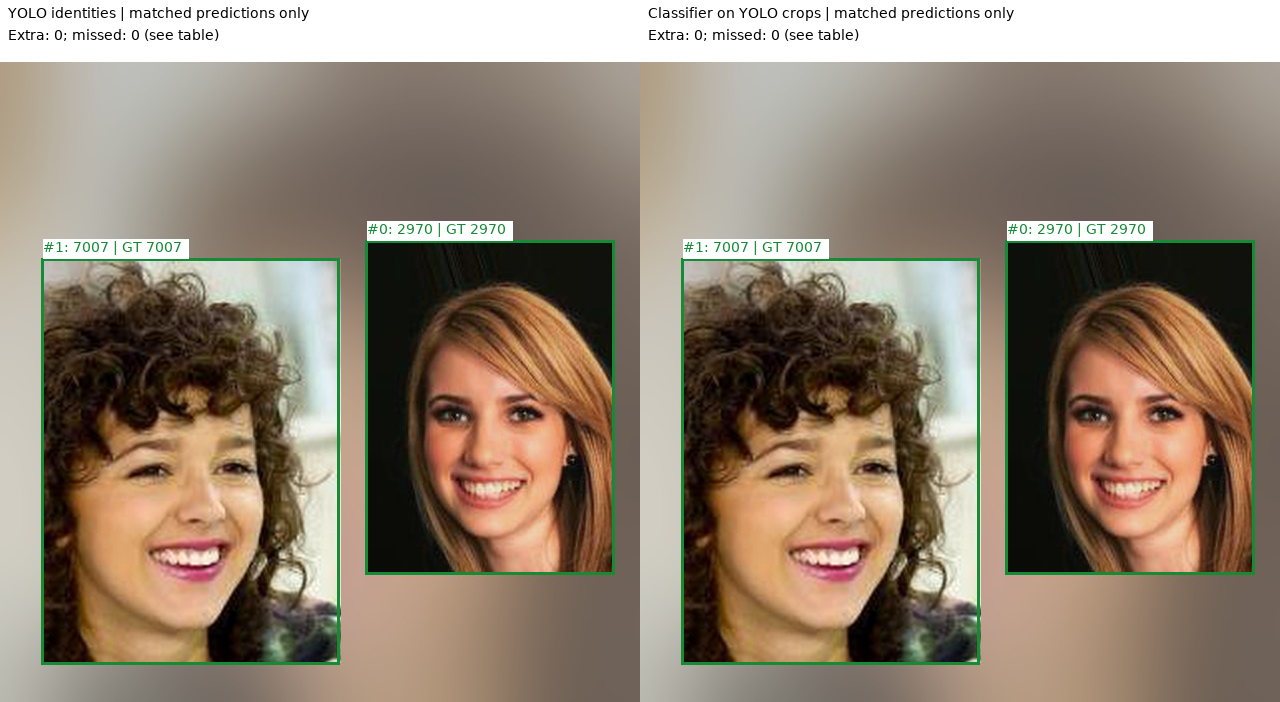


val_0001.jpg: GT=3, predictions=3, extra=0, missed=0; correct YOLO=3, classifier=3


,Pred #,GT #,True ID,YOLO ID,YOLO score,Classifier ID,Classifier score,Outcome
0,0,1,4428,4428,1.000,4428,0.913,Both correct
1,1,2,797,797,0.996,797,0.986,Both correct
2,2,0,2336,2336,0.970,2336,0.892,Both correct


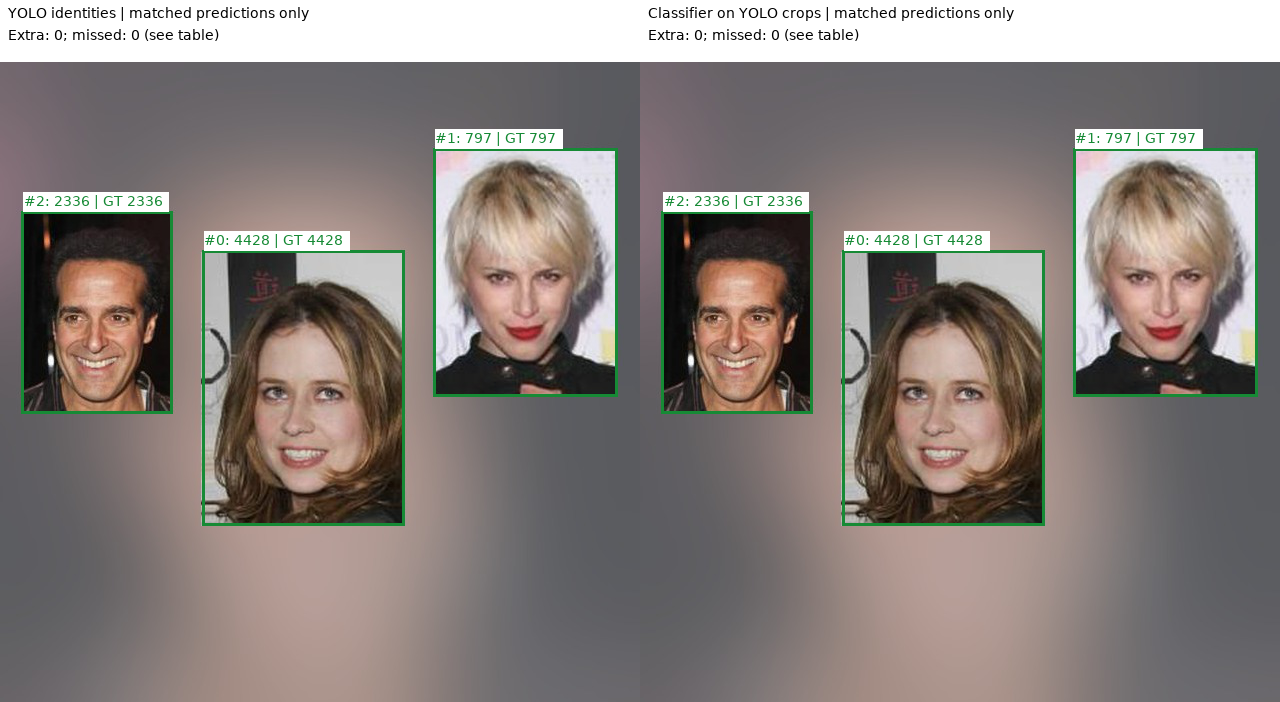


val_0002.jpg: GT=4, predictions=5, extra=1, missed=0; correct YOLO=3, classifier=3


,Pred #,GT #,True ID,YOLO ID,YOLO score,Classifier ID,Classifier score,Outcome
0,0,3,8335,8335,0.991,8335,0.997,Both correct
1,1,1,7,7,0.985,7,1.000,Both correct
2,2,2,3,8335,0.838,3,0.989,Corrected by classifier
3,3,0,4422,4422,0.804,2970,0.608,Changed to wrong ID
4,4,-,-,3,0.451,3,0.991,Extra / unmatched


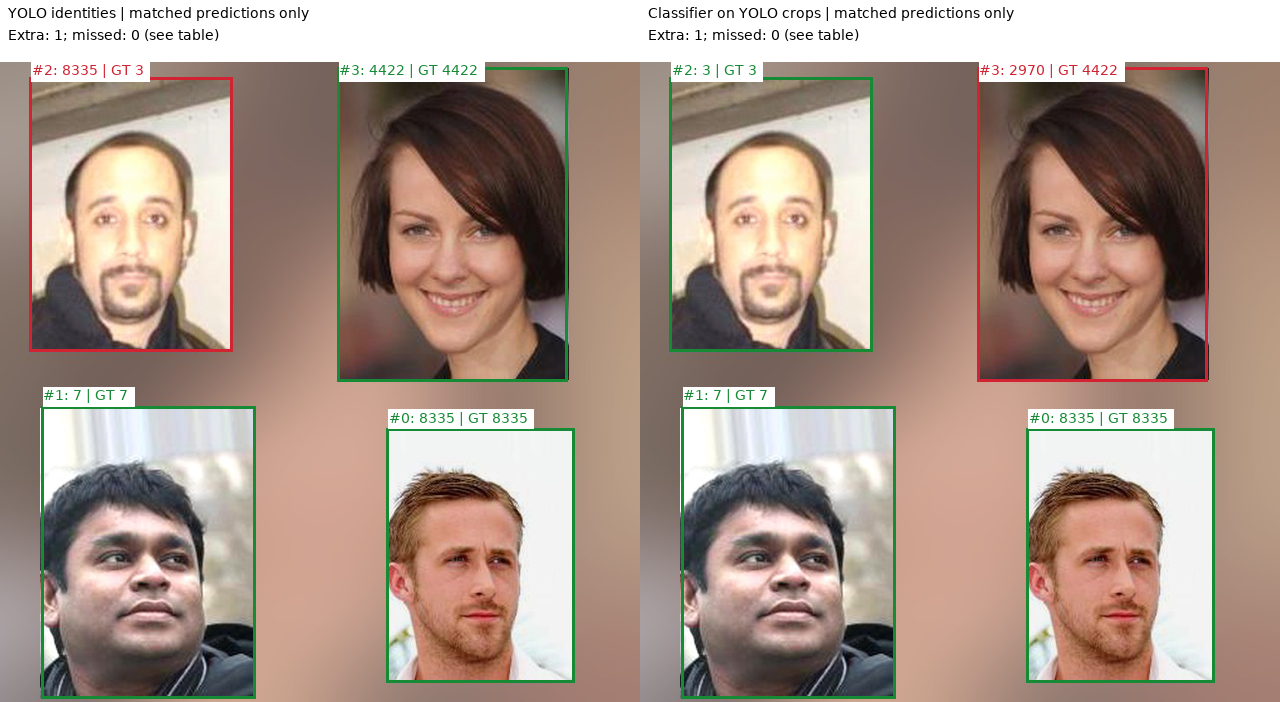


val_0003.jpg: GT=5, predictions=5, extra=0, missed=0; correct YOLO=5, classifier=5


,Pred #,GT #,True ID,YOLO ID,YOLO score,Classifier ID,Classifier score,Outcome
0,0,4,7007,7007,0.999,7007,1.000,Both correct
1,1,3,10002,10002,0.997,10002,0.793,Both correct
2,2,1,5695,5695,0.996,5695,0.992,Both correct
3,3,2,2619,2619,0.989,2619,1.000,Both correct
4,4,0,1212,1212,0.985,1212,1.000,Both correct


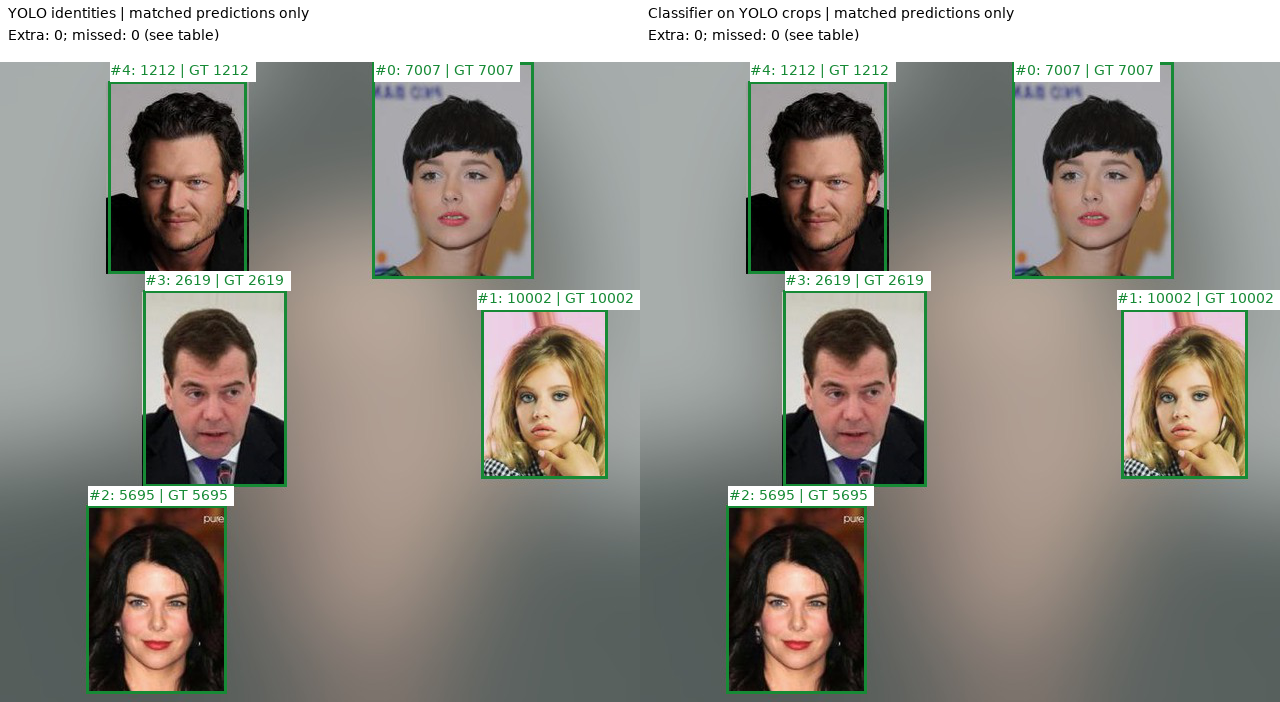


val_0004.jpg: GT=9, predictions=12, extra=3, missed=0; correct YOLO=6, classifier=7


,Pred #,GT #,True ID,YOLO ID,YOLO score,Classifier ID,Classifier score,Outcome
0,0,2,4428,4428,0.997,4428,0.995,Both correct
1,1,5,7,7,0.995,7,0.674,Both correct
2,2,3,797,797,0.987,797,0.999,Both correct
3,3,0,2970,4428,0.979,4428,0.817,Both wrong
4,4,4,4422,4422,0.957,4422,0.731,Both correct
5,5,7,8335,8335,0.902,3,0.888,Changed to wrong ID
6,6,6,3,7,0.898,3,1.000,Corrected by classifier
7,7,-,-,3,0.863,3,1.000,Extra / unmatched
8,8,8,1212,1212,0.858,1212,0.811,Both correct
9,9,1,2336,797,0.676,2336,0.877,Corrected by classifier


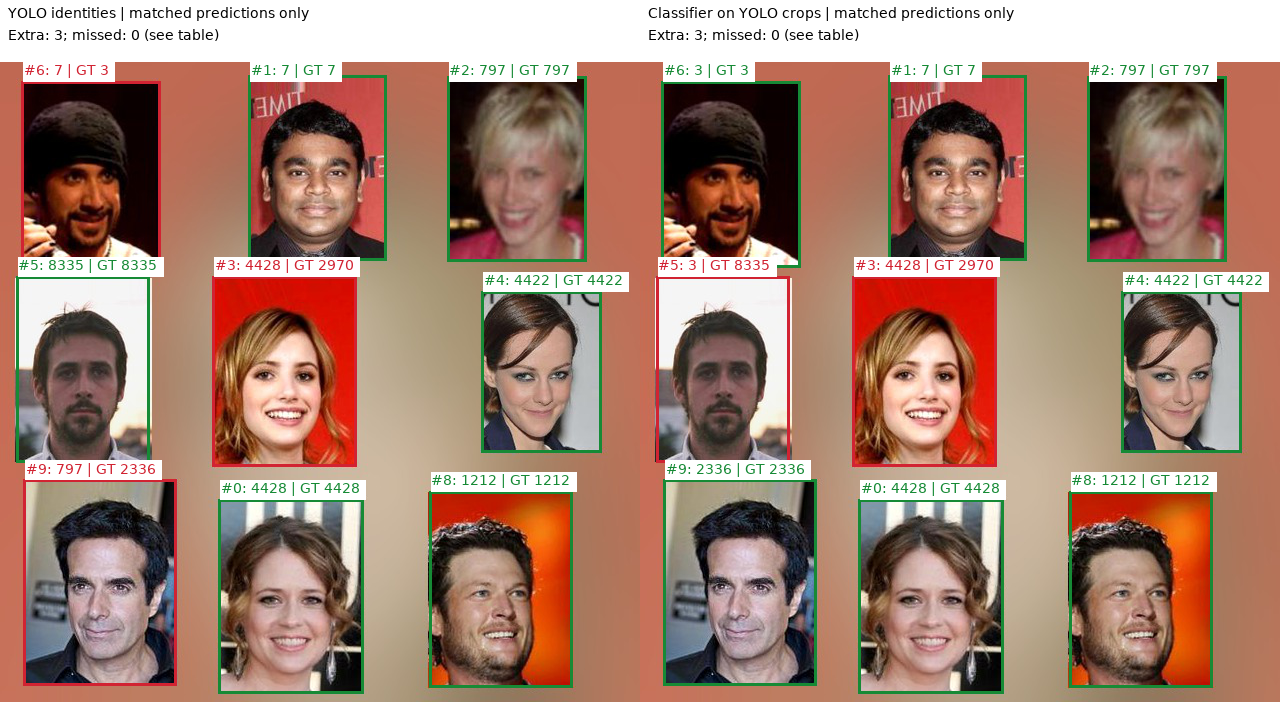


val_0005.jpg: GT=2, predictions=2, extra=0, missed=0; correct YOLO=2, classifier=2


,Pred #,GT #,True ID,YOLO ID,YOLO score,Classifier ID,Classifier score,Outcome
0,0,0,5695,5695,0.996,5695,0.937,Both correct
1,1,1,2619,2619,0.994,2619,0.997,Both correct


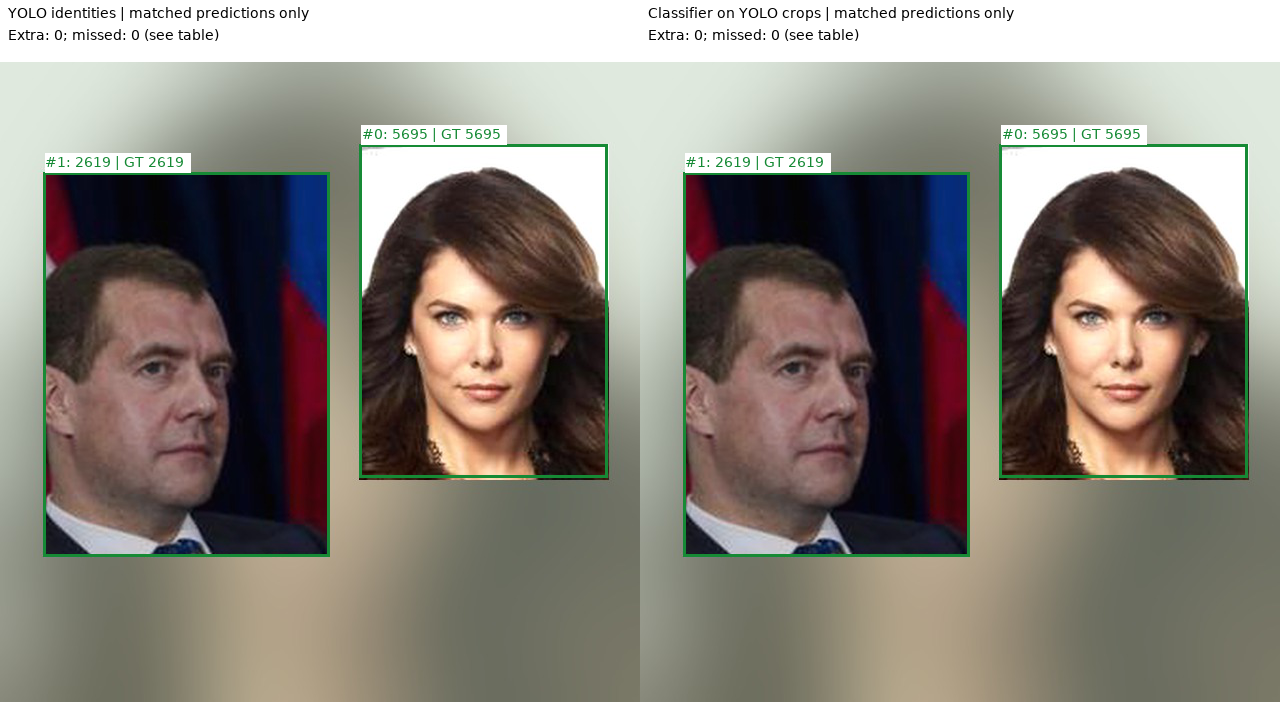

In [5]:
from PIL import Image as PILImage, ImageDraw, ImageFont

# Read saved matches; do not rerun matching, inference, NMS or policy selection.
verify_complete(RUN_DIR)
review_frames = json.loads((RUN_DIR / 'predictions.json').read_text(encoding='utf-8'))
review_counts = pd.read_csv(RUN_DIR / 'per_image.csv')
print('All 39 validation frames: same original predicted boxes for both methods.')
display(review_counts[['ground_truth', 'predictions', 'localized', 'extra',
                       'missed', 'yolo_correct', 'classifier_correct']].sum().to_frame('Total').T)
print('Previews: first six filenames. Tables retain every prediction; images show matched boxes only.')


def prediction_review(frame):
    rows = []
    matched_gt = set()
    for index, prediction in enumerate(frame['predictions']):
        target = prediction['matched_gt_index']
        true_id = frame['ground_truth'][target]['identity'] if target is not None else None
        yolo_ok = target is not None and prediction['yolo_identity'] == true_id
        classifier_ok = target is not None and prediction['classifier_identity'] == true_id
        if target is None:
            outcome = 'Extra / unmatched'
        elif yolo_ok and classifier_ok:
            outcome = 'Both correct'
        elif classifier_ok:
            outcome = 'Corrected by classifier'
        elif yolo_ok:
            outcome = 'Changed to wrong ID'
        else:
            outcome = 'Both wrong'
        if target is not None:
            matched_gt.add(target)
        rows.append({'Pred #': str(index), 'GT #': str(target) if target is not None else '-',
                     'True ID': str(true_id) if true_id is not None else '-',
                     'YOLO ID': str(prediction['yolo_identity']),
                     'YOLO score': f"{prediction['yolo_confidence']:.3f}",
                     'Classifier ID': str(prediction['classifier_identity']),
                     'Classifier score': f"{prediction['classifier_confidence']:.3f}",
                     'Outcome': outcome})
    for target, truth in enumerate(frame['ground_truth']):
        if target not in matched_gt:
            rows.append({'Pred #': '-', 'GT #': str(target), 'True ID': str(truth['identity']),
                         'YOLO ID': '-', 'YOLO score': '-', 'Classifier ID': '-',
                         'Classifier score': '-', 'Outcome': 'Missed'})
    return pd.DataFrame(rows)


try:
    review_font = ImageFont.truetype('DejaVuSans.ttf', 14)
except OSError:
    try:
        review_font = ImageFont.truetype('arial.ttf', 14)
    except OSError:
        review_font = ImageFont.load_default()

for frame in sorted(review_frames, key=lambda item: item['image'])[:6]:
    counts = review_counts.loc[review_counts['image'] == frame['image']].iloc[0]
    print(f"\n{Path(frame['image']).name}: GT={int(counts['ground_truth'])}, "
          f"predictions={int(counts['predictions'])}, extra={int(counts['extra'])}, "
          f"missed={int(counts['missed'])}; correct YOLO={int(counts['yolo_correct'])}, "
          f"classifier={int(counts['classifier_correct'])}")
    display(prediction_review(frame))
    with PILImage.open(ROOT / 'data/m2_detection' / frame['image']) as source_image:
        original = source_image.convert('RGB')
    width, height = original.size
    panels = []
    for method, title in [('yolo', 'YOLO identities'), ('classifier', 'Classifier on YOLO crops')]:
        panel = PILImage.new('RGB', (width, height + 62), 'white')
        panel.paste(original, (0, 62))
        draw = ImageDraw.Draw(panel)
        draw.text((8, 5), title + ' | matched predictions only', fill='black', font=review_font)
        draw.text((8, 27), f"Extra: {int(counts['extra'])}; missed: {int(counts['missed'])} (see table)",
                  fill='black', font=review_font)
        labels = []
        for index, prediction in enumerate(frame['predictions']):
            target = prediction['matched_gt_index']
            if target is None:
                continue
            true_id = frame['ground_truth'][target]['identity']
            correct = prediction[method + '_identity'] == true_id
            color = '#168a35' if correct else '#d12332'
            x1, y1, x2, y2 = prediction['xyxy']
            draw.rectangle((x1, y1 + 62, x2, y2 + 62), outline=color, width=3)
            label = f"#{index}: {prediction[method + '_identity']} | GT {true_id}"
            text_box = draw.textbbox((0, 0), label, font=review_font)
            label_width = text_box[2] - text_box[0] + 6
            tx, ty = max(0, min(x1 + 2, width - label_width)), max(62, y1 + 62 - 19)
            labels.append((tx, ty, label_width, label, color))
        # Draw labels last so neighboring box borders cannot cross the text.
        for tx, ty, label_width, label, color in labels:
            draw.rectangle((tx, ty, tx + label_width, ty + 19), fill='white')
            draw.text((tx, ty), label, fill=color, font=review_font)
        panels.append(panel)
    pair = PILImage.new('RGB', (width * 2, height + 62), 'white')
    pair.paste(panels[0], (0, 0))
    pair.paste(panels[1], (width, 0))
    display(pair)


## Policy selection

Eight candidates were compared using saved validation predictions. The highest micro identity F1 selected additional class-agnostic NMS at IoU `0.7` and a classifier conflict threshold of `0.9`.

Keep agreeing IDs. On disagreement, use the classifier ID if its own score is at least `0.9`; otherwise use YOLO. This is not an unknown-identity rejection threshold.

See the [candidate comparison](../m4_artifacts/validation_policy_comparison.csv), [selected metrics](../m4_artifacts/validation_selected_policy_metrics.json) and [frozen policy](../m4_artifacts/integration_policy.json). Test results are in [Notebook 10](10_m4_final_evaluation.ipynb).
